# Rosella: sizing of the H4 12S quadplane with the bought boom tube

Rosella is a VTOL quadplane. It has the Currawong wing and tail, a new fuselage, two lift booms with a rotor at each end (layout
H4), and the Currawong nose propeller for cruise. This notebook sizes the lift propulsion system and the boom for the least mission
energy. The tube of the boom is fixed (the tail boom tube): outer diameter 25.4 mm, inner diameter 23.4 mm, wall 1.0 mm, E = 80 GPa. The team chose H4 with 12 cells (12S).

How to read it:

1. The components are built in code, one cell for each group. Each number has units and a source. A number with
   `placeholder=True` is a stand-in that waits for a measurement or a maker figure.
2. The model (`model.QuadplaneModel`) turns the components into one optimisation problem. `optimise.ladder` solves it in five
   levels of fidelity, L0 (momentum theory) to L4 (blade element theory in every flight state).
3. The result is checked by hand, saved to `settings/rosella.json`, and drawn.

How to run it: `python -m aeroplan setup AeroSandbox` makes the Python (once for each computer). Copy the Proptimiser design and state
files of the lift blade and of the cruise blade by hand into `work/aerosandbox/redback/proptimiser` and
`work/aerosandbox/currawong/proptimiser`. Then run the notebook in the kernel "AeroPlan AeroSandbox". The last cell is an
interactive window: it needs the notebook open, GitHub shows no widgets.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

HERE = Path.cwd()
TOOL = HERE if (HERE / "component.py").exists() else HERE.parent       # the notebook sits in tools/aerosandbox/notebooks
sys.path.insert(0, str(TOOL))

import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot
from component import P, Airframe, Battery, Cables, Control, CruiseRotor, ESC, Fuselage, Material, Motor, PointMass, Rotor, Spec, Tube
from mission import Mission
from model import DESIGN_VARS, QuadplaneModel
from optimise import evaluate, init_from, ladder, ladder_table
from result import Result

warnings.filterwarnings("ignore")
U = "user requirement 2026-10-17"
plot.style()
pd.set_option("display.float_format", lambda x: f"{x:.5g}")

## 2. The components

### 2.1 The boom tube

The tube is an off the shelf component and needs to be tested further, but is defined based on some aero testing and similar manufacturer data.
The boom (`Tube`) holds the layout of the boom (clamp shift `dx`, hub distance `a`, lateral position `y`) and its limits. The tube
size `r_o` and `t` start as free params. Section 3 fixes them.

The first bending frequency f1 of a boom end stays below the band hover 1P
minus 20 %. Every speed from hover to full throttle is then above the boom mode.

In [2]:
roll_wrapped = Material(
    "roll_wrapped",
    E_Pa=P(62.7e9, "Pa", "Rock West Composites SKU 45026, theoretical properties (classical lamination theory, reference only): 9.1 Msi tension; the page header shows 8.2 Msi, a conflict"),
    E_c_Pa=P(54.5e9, "Pa", "same page: 7.9 Msi compression"),
    density_kg_m3=P(1522.0, "kg/m3", "page gives 0.055 with no unit; read as lb/in3 (not confirmed)", placeholder=True),
    tensile_strength_Pa=P(372e6, "Pa", "same page: 54 ksi"),
    compressive_strength_Pa=P(359e6, "Pa", "same page: 52 ksi"),
    G_Pa=P(4.5e9, "Pa", "stand-in: typical 2x2 twill tube shear modulus; no maker figure found", placeholder=True),
    buckling_knockdown=P(0.5, "nd", "stand-in. NASA SP-8007 gives gamma = 1 - 0.901 (1 - exp(-phi)), phi = sqrt(R/t) / 29.8 (axial) and 0.731 in place of 0.901 for bending; the formula is from a search snippet, check it before use", placeholder=True))
bought_tube = roll_wrapped.with_E(80e9, "bought_tube")
bought_tube.params["E_Pa"].source = "user 2026-10-21: the bought lift boom tube, E = 80 GPa. E_c keeps the ratio E_c / E of the roll-wrapped data"

boom = Tube(
    "boom",
    r_o=P(0.020, "m", "start value", free=True, lo=0.008, hi=0.045, scale=1e-2),
    t=P(0.0015, "m", "start value", free=True, lo=0.001, hi=0.005, scale=1e-3),
    y=P(0.65, "m", "start value", free=True, lo=0.35, hi=1.0, scale=0.65),
    dx=P(0.0, "m", "boom clamp shift from the wing root mid-chord (stand-in until the spar x is in the tree)", placeholder=True, free=True, lo=-0.35, hi=0.35, scale=0.1),
    a=P(0.50, "m", "start value", free=True, lo=0.25, hi=1.0, scale=0.5),
    overhang_m=P(0.06, "m", "stand-in: boom length beyond each hub", placeholder=True),
    mount_offset_m=P(0.02, "m", "stand-in: thrust line offset from the boom axis (torsion arm)", placeholder=True),
    clamp_kg=P(0.060, "kg", "stand-in: clamp at the wing, measure the part", placeholder=True),
    min_wall_m=P(0.001, "m", "user decision 2026-10-17: 1.0 mm minimum wall"),
    r_over_t_max=P(60.0, "nd", "stand-in: limit of the thin-wall tube formulas", placeholder=True),
    tip_slope_max_deg=P(2.0, "deg", "stand-in: boom tip slope at T_max", placeholder=True),
    resonance_margin=P(0.2, "nd", "stand-in: f1 stays outside 1P hover +/- 20 %. The principle (no coincidence of airframe and rotor frequency) is ISO 5109:2023. The margin is not from that text (not read)", placeholder=True),
    resonance_side=P("below", "", "user decision 2026-10-21: the boom must not be resonant at or near the hover rpm. below: f1 under the band, so hover to full throttle is above the mode. Burela and Sujit 2026 (arXiv 2607.22768, V.C) use the stricter f1 >= 1.5 x blade passing at peak rpm"),
    material=P("boom_material"))

### 2.2 Rotor, motor, ESC, battery and cables

The lift rotor is the Proptimiser blade design `MAD_FLUXER_22x6_6_jung`, scaled in radius: the chord and twist shape of the
Jung et al. 2021 T-motor blades, fitted to the MAD FLUXER 22x6.6 maker table (Fit C residuals). The motor mass, resistance and idle
current come from a fit on `data/motor_survey.csv` (the mass from the torque only). The ESC mass comes from a fit on the maker
rows of `data/esc_survey.csv`. The battery and the carbon propeller masses follow Bershadsky, Haviland and Johnson, AIAA 2016-0581. The free params `kv`, `q_cap`, `cap_Ah`, `x_m` and `scale` are design variables.

In [3]:
rotor = Rotor(
    "rotor",
    design=P("MAD_FLUXER_22x6_6_jung", "", "Proptimiser design, Jung 2021 T-motor shape fitted to the MAD FLUXER 22x6.6 maker table (Redback)"),
    design_aircraft=P("redback", "", "work folder that holds the design file and the state file"),
    reference_radius_m=P(0.2794, "m", "R_tip of the design file (D 559 mm). The scale s = R / 0.2794 gives other radii"),
    scale=P(1.0, "nd", "R / reference radius. Bounds: 406 mm to 660 mm diameter (16 in to 26 in). User decision 2026-10-17: 762 mm gained only 5.5 % energy for a 36 % extrapolation of the FLUXER blade",
            free=True, lo=0.2032 / 0.2794, hi=0.3302 / 0.2794, scale=1.0),
    cant=P(0.05, "rad", "tilt of each rotor about its radial axis; range 0 to 10 deg", free=True, lo=0.0, hi=math.radians(10.0), scale=0.1),
    blade_diameter_m=P(0.5588, "m", "MAD FLUXER 22x6.6: 22 in, converted to SI"),
    blade_pitch_m=P(0.16764, "m", "MAD FLUXER 22x6.6: 6.6 in, converted to SI. P/D is the pitch of an order sheet when the parts list gives none"),
    mass_kg=P(None), pitch_m=P(None),
    prop_g_a_in2=P(0.1207, "g/in2", "AIAA 2016-0581 Eq. 5, carbon (m = p1 (2R)^2 + p2 (2R) + p3; the text gives no p3, so p3 = 0; 2R in inch, from the figure axis)"),
    prop_g_b_in=P(-0.5122, "g/in", "same equation, p2"),
    tip_clearance_m=P(0.020, "m", "stand-in: gap between prop discs and the nearest structure", placeholder=True),
    tip_mach_max=P(0.65, "nd", "stand-in: tip Mach limit of the NeuralFoil sections", placeholder=True),
    coaxial_spacing_over_D=P(0.25, "nd", "Brazinskas et al. 2016: the 22 % loss holds for z/D > 0.25, so the pair is spaced at 0.25 D"),
    table_omega_rad_s=P([250.0, 388.0, 525.0, 663.0, 800.0], "rad/s", "numeric BEMT samples over the shaft speed range of the Opti variable"),
    table_scale=P([0.8, 1.0, 1.18], "nd", "geometric scale samples, inside the radius bounds"),
    table_v_x_m_s=P([0.0, 2.5], "m/s", "hover and the 2.5 m/s vertical climb of the mission"),
    table_poly_degree=P(3, "nd", "stand-in: lowest degree with a fit error under 1 % of CT; see the printed RMS", placeholder=True),
    momentum_omega_rad_s=P(435.0, "rad/s", "hover shaft speed of the base blade at about 37 N thrust (15 kg on 4 rotors); sets FM and the hover CT"),
    momentum_scale=P(1.0, "nd", "scale of the momentum constants"))

cruise_rotor = CruiseRotor(
    "cruise_rotor",
    design=P("Currawong_V1", "", "aircraft/currawong propeller installation 1.2.3.9 (motor X5220)"),
    design_aircraft=P("currawong", "", "work folder that holds the design file and the state file"),
    table_omega_rad_s=P([400.0, 500.0, 650.0, 800.0], "rad/s", "shaft speed range of the Opti variable of the cruise propeller"),
    table_J=P([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], "nd", "advance ratio samples"),
    table_fit_J_max=P(0.6, "nd", "the Currawong V1 blade gives CT below zero for J above 0.6; the fit covers the thrust range only"),
    table_poly_degree=P(4, "nd", "stand-in: lowest degree with a fit error under 1 % of CT", placeholder=True))

motor = Motor(
    "motor",
    kv=P(150.0, "rpm/V", "start value", free=True, lo=60.0, hi=450.0, scale=150.0),
    q_cap=P(3.0, "N*m", "torque the motor holds for the 180 s peak current, (Imax - I0)/Kv of the survey", free=True, lo=0.5, hi=9.0, scale=3.0),
    survey=P("data/motor_survey.csv", "", "sourced motor table (tools/aerosandbox/data)"),
    kv_min=P(60.0, "rpm/V", "rows of the survey used by the fit"), kv_max=P(450.0, "rpm/V", "rows of the survey used by the fit"),
    mass_min_g=P(150.0, "g", "rows of the survey used by the fit"), mass_max_g=P(1600.0, "g", "rows of the survey used by the fit"),
    mass_kg=P(None), rm_ohm=P(None), i0_A=P(None),
    mount_kg=P(0.045, "kg", "stand-in: Redback motor mount mass, check against aircraft/redback", placeholder=True))

esc = ESC(
    "esc",
    survey=P("data/esc_survey.csv", "", "maker ESC rows, Hobbywing XRotor Pro H series and T-Motor ALPHA (tools/aerosandbox/data); the fit uses the rows rated for the pack cell count"),
    peak_factor=P(1.2, "nd", "stand-in: ESC rated at 1.2 times the peak motor current", placeholder=True),
    re_ohm=P(0.020, "ohm", "stand-in: ESC resistance, inside the 9 to 45 mOhm range of AIAA 2016-0581 section II.B", placeholder=True),
    duty_max=P(0.95, "nd", "stand-in: ESC duty limit with a margin for the control", placeholder=True),
    mass_kg=P(None), current_A=P(None))

battery = Battery(
    "battery",
    cells_s=P(12, "nd", "team decision: H4 12S"),
    cap_Ah=P(14.0, "A*h", "start value", free=True, lo=2.0, hi=60.0, scale=14.0),
    x_m=P(0.0, "m", "x of the pack centre; between the bay limits (stand-in: Currawong bay)", placeholder=True, free=True, lo=-0.45, hi=0.40, scale=0.1),
    cell_nominal_V=P(3.7, "V", "LiPo, Gens ace listing: 22.2 V for 6S"),
    cell_end_V=P(3.5, "V", "stand-in: cell voltage at the end of the reserve, under no load", placeholder=True),
    cell_resistance_mohm=P(5.0, "mohm", "stand-in: makers say 'low IR' only. Measure the packs or read the maker sheet", placeholder=True),
    c_rate_max=P(25.0, "1/h", "Gens ace / Tattu 4500 mAh 25C pack, maximum continuous"),
    usable_fraction=P(0.80, "nd", "stand-in: usable depth of discharge of a LiPo pack", placeholder=True),
    eq4_p1=P(0.026373, "g/(mAh)", "AIAA 2016-0581 Eq. 4: m = (p1 s + p2) C, g, C in mAh"),
    eq4_p2=P(2.0499e-05, "g/(mAh)", "AIAA 2016-0581 Eq. 4"),
    cal_cells_s=P(6, "nd", "calibration pack: Gens ace / Tattu 4500 mAh 22.2 V 25C 6S1P"),
    cal_capacity_Ah=P(4.5, "A*h", "calibration pack capacity"),
    cal_mass_kg=P(0.631, "kg", "Propalyser component for the NXE 6S 4500 pack (631 g, 99.9 Wh). The Gens ace listing says 610 g"),
    mass_kg=P(None))

cables = Cables(
    "cables",
    current_density_A_m2=P(10.0e6, "A/m2", "stand-in: 10 A/mm2 for short silicone leads in free air; ampacity table not found", placeholder=True),
    insulation_factor=P(1.4, "nd", "stand-in: mass of insulation as a fraction on the copper mass", placeholder=True),
    run_extra_m=P(0.15, "m", "stand-in: extra lead length for routing at each end of the run", placeholder=True))

### 2.3 Airframe, fuselage and fixed masses

The wing, the tail and the tail boom come from `aircraft/currawong` in the source tree. The CG sits at the neutral point less
10 % of the mean aerodynamic chord. The new fuselage is a superellipse body sized for the battery bay.

The avionics has two items: the flight avionics (the weighed Currawong avionics) and the avionics projects (a stand-in).
The payload is the 410 g cargo. It is released at the deployment, so the deployment hover, the landing and the reserve
hover fly without it.

In [4]:
airframe = Airframe(
    "airframe",
    base=P("currawong", "", "wing, htail, fin and tail boom come from aircraft/currawong"),
    static_margin_target=P(0.10, "nd", "user decision 2026-10-17: CG = NP - SM x MAC; 10 % MAC is the design choice", placeholder=True),
    cg_nose_prop_m=P(0.800, "m", "user measurement 2026-10-17: CG about 0.800 m behind the nose propeller hub (estimate; the CG is a design output)"))

fuselage = Fuselage(
    "fuselage",
    stations=P(21, "nd", "frames of the body"),
    width_m=P(0.24, "m", "stand-in: the Currawong V1 maximum width (aircraft/currawong fuselage frames); size the bay for the real battery", placeholder=True),
    height_m=P(0.18, "m", "stand-in: the Currawong V1 maximum height", placeholder=True),
    superellipse_n=P(2.5, "nd", "section shape exponent"),
    z_centre_m=P(0.02, "m", "axis height of the body"),
    nose_behind_hub_m=P(0.07, "m", "Currawong V1 is 0.07 m behind the nose propeller hub at the nose"),
    x_tail_m=P(0.561261779785036, "m", "user 2026-10-21: the pod tail end stays 561 mm aft of the wing root leading edge (the start of the old tail boom). The new tail boom starts inside the pod, so the pod end no longer follows the boom"),
    mass_kg_per_m2=P(1.0, "kg/m2", "stand-in: carbon/glass shell area density with bulkheads", placeholder=True),
    bay_x_m=P([-0.45, 0.40], "m", "stand-in: the battery centre can sit between these x (Currawong bay)", placeholder=True),
    battery_Wh_per_L=P(330.0, "Wh/L", "stand-in: LiPo pack energy density for the bay check", placeholder=True))

avionics = PointMass("avionics", projects_mass_kg=P(1.01, "kg", "user 2026-10-21: avionics projects (project equipment). Stand-in value. The flight avionics is the Currawong AVIONICS-REST mass (0.609 kg, weighed)", placeholder=True),
                     power_W=P(25.0, "W", "stand-in: flight avionics, avionics projects and servos", placeholder=True))
landing_gear = PointMass("landing_gear", mass_kg=P(0.60, "kg", "stand-in: VTOL skids; the Currawong gear is 1.32 kg", placeholder=True),
                         x_m=P(0.16, "m", "Currawong gear x"), z_m=P(-0.10, "m", "gear height"))
cargo = PointMass("cargo", mass_kg=P(0.410, "kg", "user 2026-10-21: payload 410 g, released at the deployment (aircraft/redback 1.2.17 cargo)"),
                  x_from_cg=P(0.0, "m", "cargo sits at the CG"))

### 2.4 Mission, limits, control and cruise aerodynamics

The mission is Redback flight 00000171 with 10 endurance laps in place of 1.

In [5]:
mission = Mission(
    "mission",
    climb_height_m=P(93.0, "m", "Redback flight 00000171 (2026-09-15), work/ardupilot/redback/00000171.BIN"),
    climb_rate_m_s=P(2.6, "m/s", "same flight"),
    transit_m=P(656.0, "m", "same flight"),
    lap_length_m=P(3370.0, "m", "same flight, 10 endurance laps in place of 1"),
    lap_count=P(10, "nd", "same flight, 10 endurance laps in place of 1"),
    rtl_m=P(660.0, "m", "same flight"),
    survey_lines=P(6, "nd", "same flight"), survey_line_length_m=P(259.0, "m", "same flight"),
    survey_turn_bank_deg=P(30.0, "deg", "same flight"),
    deployment_hover_s=P(60.0, "s", "Mk4 sheet for the deployment hover"),
    reserve_hover_s=P(300.0, "s", U + " (5 min reserve hover battery)"),
    vtol_climb_m=P(30.0, "m", "vertical take-off climb height"), vtol_climb_rate_m_s=P(2.5, "m/s", "vertical climb rate"),
    vtol_descent_rate_m_s=P(1.5, "m/s", "vertical descent rate"), transition_s=P(15.0, "s", "transition time, each way"))

limits = Spec(
    "limits",
    mtow_kg=P(15.0, "kg", U),
    thrust_to_weight=P(2.5, "nd", U + " (hover thrust at full throttle over MTOW)"),
    load_factor=P(3.0, "nd", U + " (3 g boom strength)"),
    safety_factor=P(1.5, "nd", "stand-in: the usual factor for ultimate load on a composite part", placeholder=True))

control = Control(
    "control",
    bandwidth_rad_s=P(2.0, "rad/s", "ADS-33E-PRF, 'all other MTEs and divided attention', Level 1 (Ivler et al., Toward a UAS Handling Qualities Specification, Methodology)"),
    bandwidth_length_m=P(11.9, "m", "derived: 1.8 ft x 21.7 = 39 ft (Ivler et al., Table 2 and Eq. 1)"),
    amplitude_rad=P(0.1745, "rad", "stand-in: 10 deg, the heading tolerance of the Ivler MTE tables. Not a figure for roll or pitch", placeholder=True),
    margin=P(1.2, "nd", "stand-in: factor on the required angular acceleration", placeholder=True),
    yaw_rad_s2=P(1.5, "rad/s2", "user decision 2026-10-17 after a sweep of 0.5 to 3.0 (cost 2 Wh above 1.0, cant 5.6 deg). No yaw figure in Ivler et al.", placeholder=True),
    idle_thrust_fraction=P(0.15, "nd", "stand-in: lowest rotor thrust in flight as a fraction of the hover thrust", placeholder=True),
    k_int=P(1.28, "nd", "derived: 1 / (1 - 0.22), the power factor at equal thrust (Brazinskas et al. 2016, abstract: 22 % loss for torque-balanced coaxial at z/D > 0.25). Leishman and Syal case 4b gives 1.26"))

cruise_aero = Spec(
    "cruise_aero",
    boom_cf=P(0.0045, "nd", "stand-in: skin friction of a smooth tube at Re about 1e6 (flat plate, turbulent)", placeholder=True),
    boom_form_factor=P(1.2, "nd", "stand-in: Hoerner form factor of a cylinder along the flow", placeholder=True),
    nacelle_cda_m2=P(0.0010, "m2", "stand-in: drag area of one motor and mount in the flow", placeholder=True),
    stopped_prop_cda_per_r2=P(0.01, "nd", "stand-in: drag area of a stopped prop aligned with the flow, per m2 of R squared", placeholder=True),
    cl_max_usable_factor=P(0.85, "nd", "stand-in: factor on the AeroBuildup CL at 12 deg", placeholder=True),
    stall_margin=P(1.3, "nd", "1.3 Vs (user plan)"),
    map_turn_radius_m=P(40.0, "m", "stand-in: 30 deg bank turns at 15 m/s", placeholder=True))

### 2.5 The model

`QuadplaneModel` holds the components by name. `layout="H4"` puts one rotor on each boom end. The number of cells is a param of the
battery.

In [6]:
model = QuadplaneModel(
    "rosella",
    {"limits": limits, "mission": mission, "airframe": airframe, "fuselage": fuselage, "boom_material": bought_tube,
     "boom": boom, "rotor": rotor, "cruise_rotor": cruise_rotor, "motor": motor, "esc": esc, "battery": battery,
     "cables": cables, "avionics": avionics, "landing_gear": landing_gear, "cargo": cargo,
     "cruise_aero": cruise_aero, "control": control},
    layout="H4")

## 3. Fix the bought tube

A fixed param is a parameter of the optimisation problem. A free param is a design variable. The table lists the design variables
that the optimiser changes. The boom tube radius and wall are no longer in it.

In [7]:
model.fix(boom__r_o=0.0127, boom__t=0.001)
model.c["boom"].p("r_o").source = "user 2026-10-21: the lift boom tube is the tail boom tube, 25.4 mm outer diameter (outer radius 12.7 mm)"
model.c["boom"].p("t").source = "user 2026-10-21: the lift boom tube is the tail boom tube, 23.4 mm inner diameter (wall 1.0 mm)"
free = [(ck, pk, p) for ck, pk, p in model.params() if p.free]
pd.DataFrame([{"param": f"{ck}.{pk}", "start": p.value, "lo": p.lo, "hi": p.hi, "units": p.units} for ck, pk, p in free]).set_index("param")

,start,lo,hi,units
param,,,,
boom.y,0.65,0.35,1,m
boom.dx,0,-0.35,0.35,m
boom.a,0.5,0.25,1,m
rotor.scale,1,0.72727,1.1818,nd
rotor.cant,0.05,0,0.17453,rad
motor.kv,150,60,450,rpm/V
motor.q_cap,3,0.5,9,N*m
battery.cap_Ah,14,2,60,A*h
battery.x_m,0,-0.45,0.4,m


In [8]:
ph = model.placeholders()
print(f"{len(ph)} params are stand-ins (placeholder=True). The ones that set the result:")
for k in ("boom_material.density_kg_m3", "boom_material.buckling_knockdown", "boom.resonance_margin", "boom.clamp_kg",
          "boom.overhang_m", "motor.mount_kg", "control.margin", "control.yaw_rad_s2", "esc.peak_factor", "battery.usable_fraction"):
    print("  ", k, "->", model.c[k.split(".")[0]].params[k.split(".")[1]].value)

45 params are stand-ins (placeholder=True). The ones that set the result:
   boom_material.density_kg_m3 -> 1522.0
   boom_material.buckling_knockdown -> 0.5
   boom.resonance_margin -> 0.2
   boom.clamp_kg -> 0.06
   boom.overhang_m -> 0.06
   motor.mount_kg -> 0.045
   control.margin -> 1.2
   control.yaw_rad_s2 -> 1.5
   esc.peak_factor -> 1.2
   battery.usable_fraction -> 0.8


## 4. Solve

The ladder solves L0 to L4. Each level has an elastic feasibility phase and an optimality phase, and starts from the level below.
L0 and L1 start from five random points. The solve takes about 2 minutes.

Ladder H4_12S
level status            s    M kg    E Wh   D mm     kv  worst 5 constraints (margin)
L0    ok              1.2   11.90     281    660     60  energy_Wh -0.000, stall_margin_lap +0.046, stall_margin_map +0.069, mtow_kg +0.206, tip_mach_MAX_r +0.340
L1    ok              1.8   13.75     328    660    139  motor_current_front -0.000, motor_current_rear -0.000, duty_rear -0.000, motor_torque_front -0.000, motor_torque_rear -0.000
L2    ok              0.5   14.21     342    660    143  energy_Wh +0.000, duty_rear +0.000, motor_current_front +0.000, motor_torque_front +0.000, control_yaw_rad_s2 +0.000
L3    ok             16.3   14.21     342    660    143  energy_Wh +0.000, duty_rear +0.000, motor_current_front +0.000, motor_torque_front +0.000, control_yaw_rad_s2 +0.000
L4    ok             75.2   14.22     341    660    143  energy_Wh +0.000, duty_rear +0.000, motor_current_front +0.000, motor_torque_front +0.000, control_yaw_rad_s2 +0.000


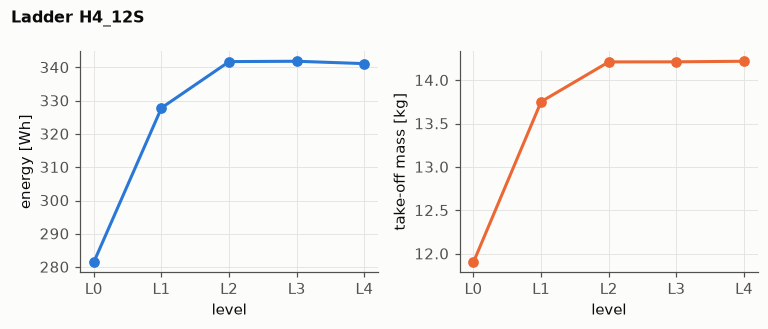

In [9]:
OUT = TOOL.parents[1] / "work" / "aerosandbox" / "rosella" / "notebook_ladder"
run = ladder(model, "L0..L4", out=OUT, multistart=5, log=lambda s: None)
print(ladder_table(run))
res = run["reports"]["L4"]
assert res.ok, "L4 did not converge"
plot.ladder_chart(run);

## 5. The design

In [10]:
d = res.design
names = {"t_boom": "boom wall", "r_boom": "boom outer radius", "y_b": "boom lateral position", "dx": "clamp shift from wing mid-chord",
         "a": "hub distance from the clamp", "scale": "rotor scale R / 279.4 mm", "kv": "motor kV", "q_cap": "motor peak torque",
         "cant": "rotor cant", "cap_Ah": "battery capacity", "x_batt": "battery x"}
units = {"t_boom": "mm", "r_boom": "mm", "y_b": "m", "dx": "m", "a": "m", "scale": "", "kv": "rpm/V", "q_cap": "N m", "cant": "deg",
         "cap_Ah": "A h", "x_batt": "m"}
conv = {"t_boom": 1e3, "r_boom": 1e3, "cant": 180 / math.pi}
rows = []
for k, (ck, pk) in DESIGN_VARS.items():
    p = model.c[ck].params[pk]
    rows.append({"variable": names[k], "value": d[k] * conv.get(k, 1.0), "unit": units[k], "state": "free" if p.free else "fixed"})
pd.DataFrame(rows).set_index("variable")

,value,unit,state
variable,,,
boom wall,1,mm,fixed
boom outer radius,12.7,mm,fixed
boom lateral position,0.4702,m,free
clamp shift from wing mid-chord,-0.056276,m,free
hub distance from the clamp,0.56452,m,free
rotor scale R / 279.4 mm,1.1818,,free
motor kV,143.08,rpm/V,free
motor peak torque,2.5281,N m,free
rotor cant,3.6159,deg,free


In [11]:
n = res["names"]
summary = pd.Series({
    "take-off mass [kg]": res.mass_kg, "mission energy [Wh]": res.energy_Wh, "nominal battery energy [Wh]": res["energy_nominal_Wh"],
    "rotor diameter [mm]": 1000 * res["D_m"], "motor mass [g]": 1000 * n["m_motor"], "propeller mass [g]": 1000 * n["m_prop"],
    "ESC mass [g]": 1000 * n["m_esc"], "battery mass [kg]": n["m_batt"], "peak motor current [A]": n["I_pk"],
    "boom length each [mm]": 1000 * n["L_boom"], "boom mass each [g]": 500 * n["m_boom"],
    "hover speed [rpm]": res["rotors"]["H_TO_f"]["rpm"], "boom f1 [Hz]": res["f1_Hz"], "hover 1P [Hz]": res["f_hover_1P_Hz"],
    "lap speed [m/s]": n["V_lap"], "survey speed [m/s]": n["V_map"], "stall speed [m/s]": n["Vs"]}, name="H4 12S, bought tube")
summary.to_frame()

,"H4 12S, bought tube"
take-off mass [kg],14.22
mission energy [Wh],341.16
nominal battery energy [Wh],426.45
rotor diameter [mm],660.4
motor mass [g],342.72
propeller mass [g],68.276
ESC mass [g],111.62
battery mass [kg],2.6934
peak motor current [A],38.967
boom length each [mm],1249


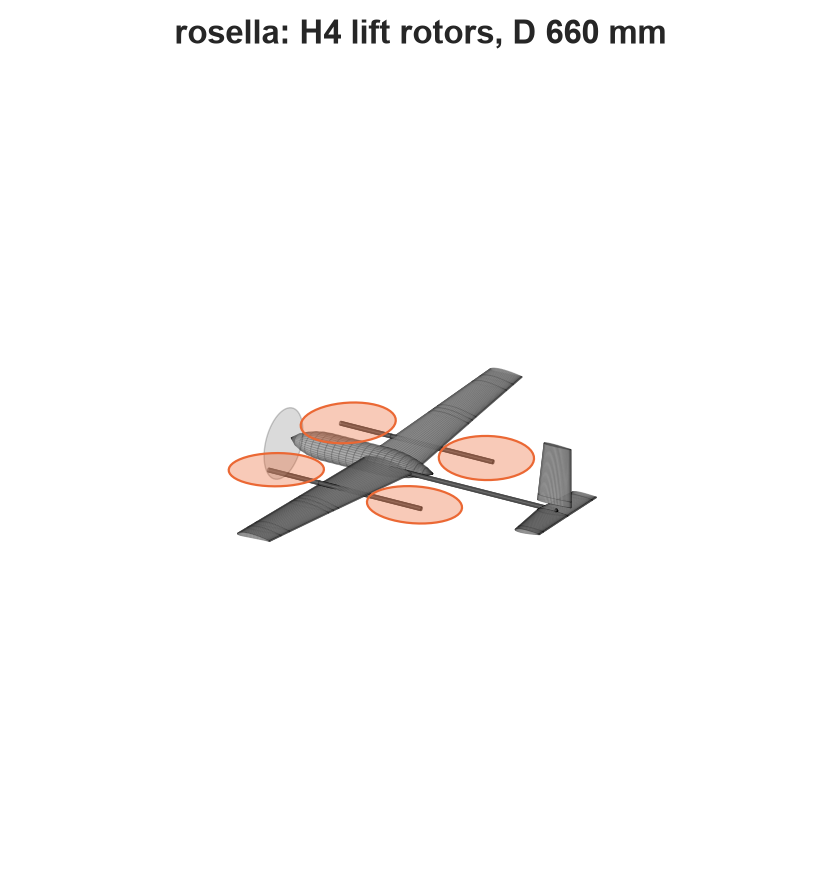

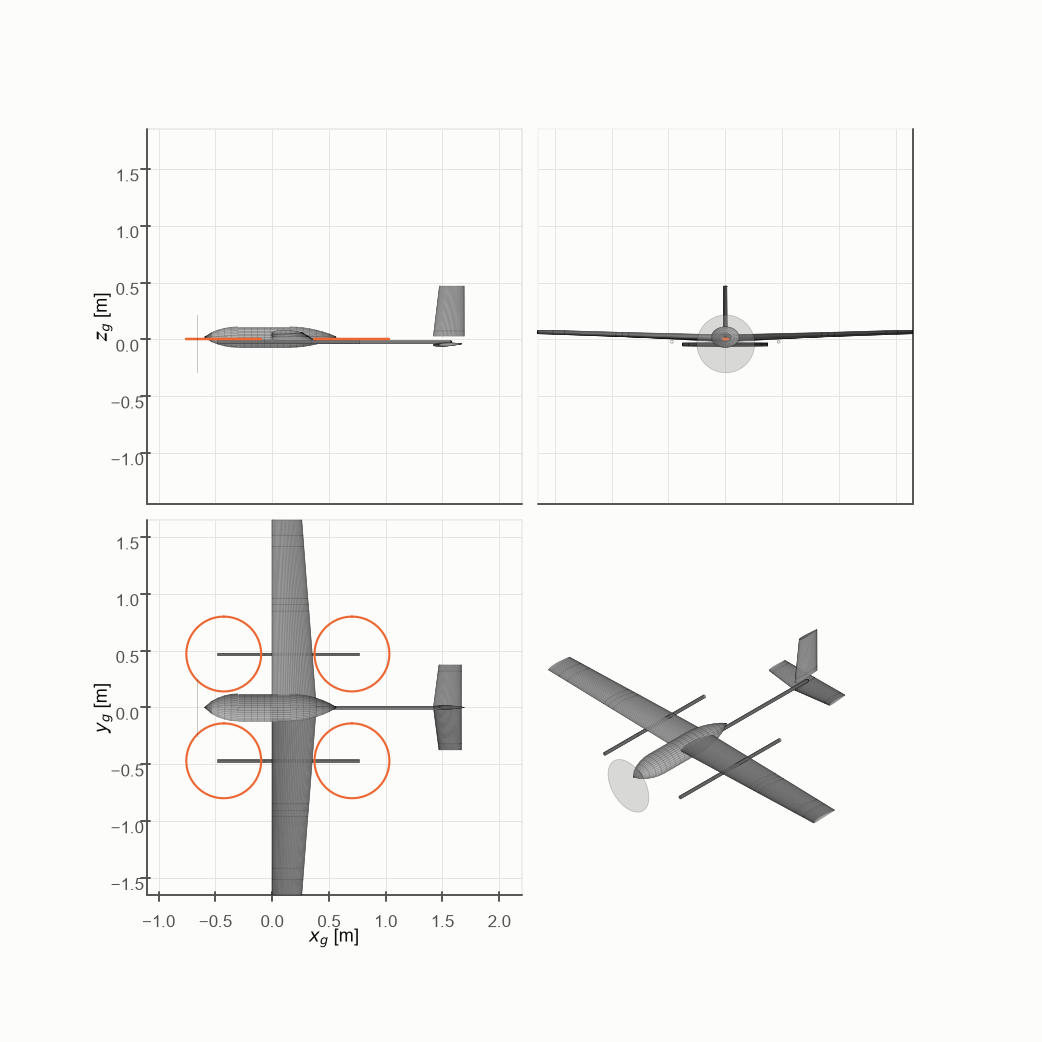

In [12]:
v = res.design
plot.view_3d(model, v);
plot.three_view(model, v);

## 6. What sets the design

A limit with a margin of 0 is active. The cost of a limit is the energy in Wh that one more unit of the limit costs, from the IPOPT
multiplier. The boom tube is not an active limit: stress, buckling and tip slope all have margin.

,value,bound,cost [Wh per unit]
limit,,,
motor_torque_front,2.5281,2.5281,10.522
motor_current_front,38.967,38.967,0.79657
motor_torque_rear,2.5281,2.5281,0.9605
motor_current_rear,38.967,38.967,0.066423
duty_rear,0.95,0.95,54.823
energy_Wh,341.16,341.16,0.28453
clear_fuselage_m,0.02,0.02,13.996
clear_rear_to_wing_TE_m,0.02,0.02,41.736
control_yaw_rad_s2,1.5,1.5,2.0862


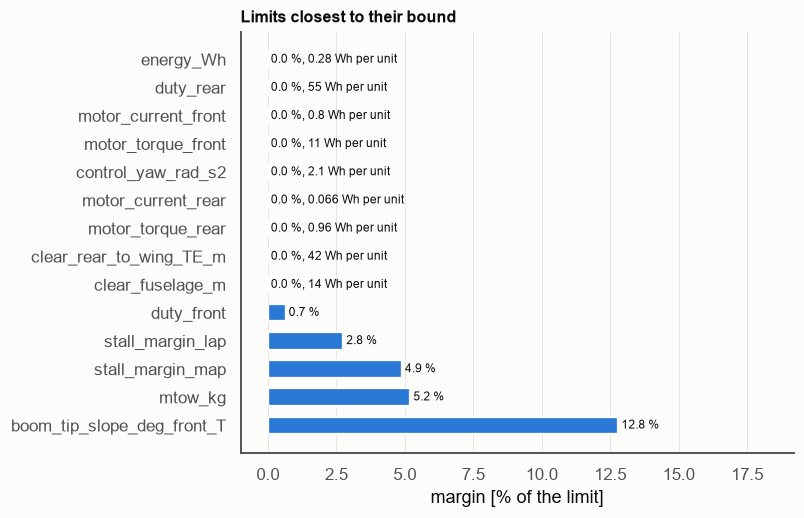

In [13]:
plot.margin_chart(res);
act = pd.DataFrame([{"limit": k, "value": c["value"], "bound": c["hi"] if c["hi"] is not None else c["lo"], "cost [Wh per unit]": c["cost_Wh_per_unit"]}
                    for k, c in res.enabled().items() if c["margin"] < 1e-3]).set_index("limit")
act

In [14]:
tube = {k: min(c["margin"] for kk, c in res.enabled().items() if kk.startswith(k)) for k in ("boom_stress", "boom_buckling", "boom_tip_slope")}
print({k: f"{100 * v:.1f} %" for k, v in tube.items()})

{'boom_stress': '53.6 %', 'boom_buckling': '90.3 %', 'boom_tip_slope': '12.8 %'}


## 7. Mass and energy

One stacked bar for each. The mass bar splits the lift units into motors, ESCs, props and mounts. The energy bar shows
the usable battery energy (nominal times the usable fraction) and the nominal energy.

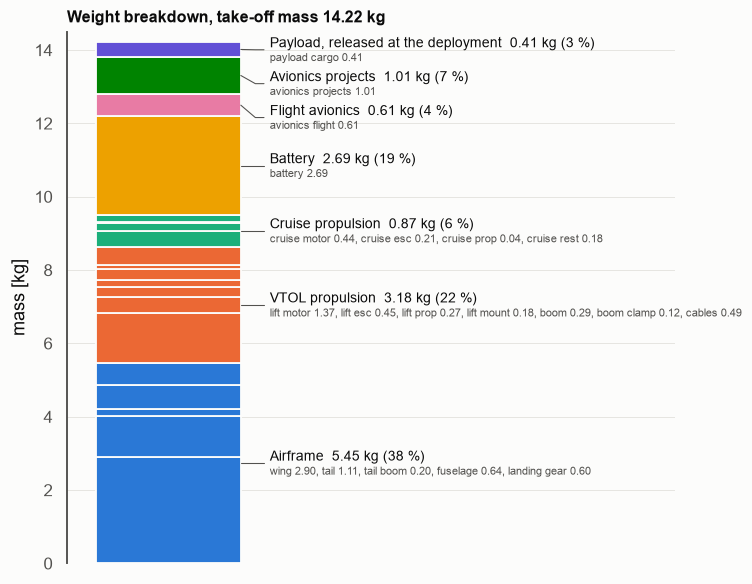

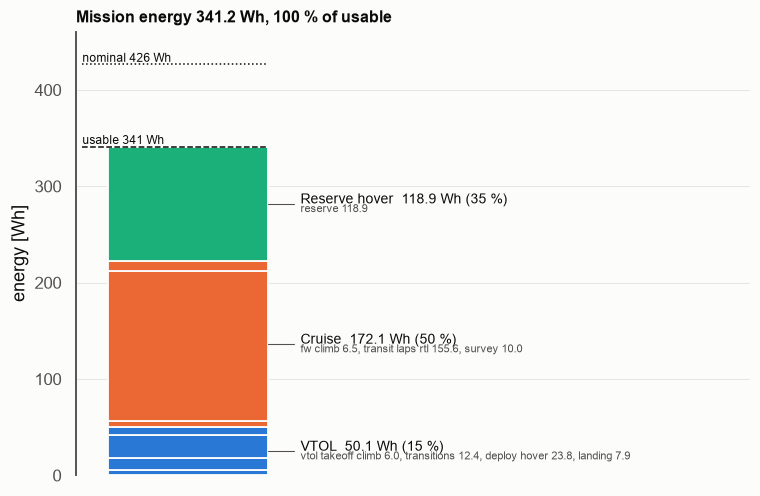

In [15]:
plot.weight_chart(res);
plot.energy_chart(res);

### 7.1 Motor and ESC mass against maker data

The motor mass is a power law of the torque q_cap only: the rows of one motor frame with other windings have the same
mass. The ESC mass is a power law of the continuous current, fitted on the maker rows rated for 12S. AIAA 2016-0581 Eq. 2
(0.84 g/A) is drawn for comparison: it gives about a third of the maker masses. The diamond is the design.

motor: m = 192 q^0.627 g, 38 rows, log RMS 0.209
ESC:   m = 3.29 I^0.917 g, 9 rows, log RMS 0.354


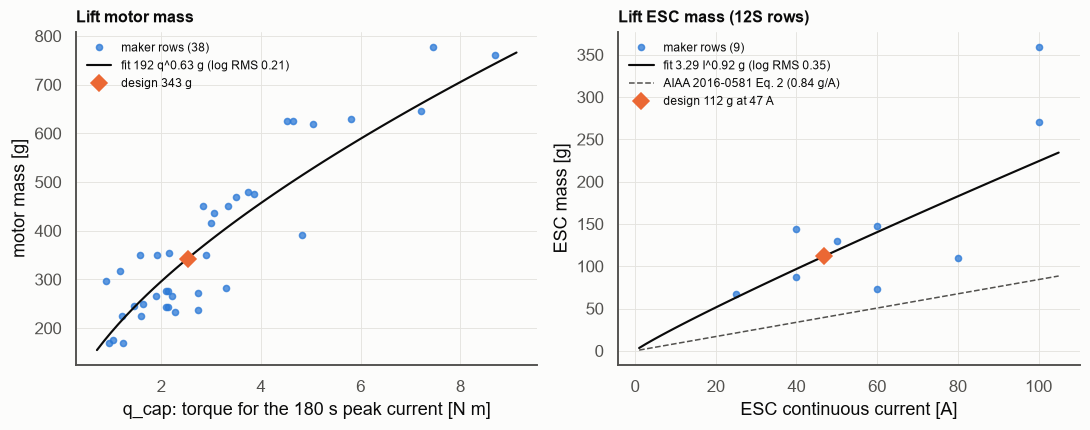

In [16]:
plot.fit_chart(model, res);
from component import esc_model, motor_model
mm, em = motor_model(model.c["motor"]), esc_model(model.c["esc"], int(model.c["battery"]["cells_s"]))
print(f"motor: m = {math.exp(mm.mass_fit[0]):.0f} q^{mm.mass_fit[1]:.3f} g, {mm.n} rows, log RMS {mm.mass_rms:.3f}")
print(f"ESC:   m = {math.exp(em.fit[0]):.2f} I^{em.fit[1]:.3f} g, {em.n} rows, log RMS {em.rms:.3f}")

## 8. Lift blade check against Jung et al. 2021

Jung et al. 2021 (Unmanned Systems 9(4) 321-332, CC BY 4.0) scanned 22 off-the-shelf blades of 381 mm to 1016 mm. The file
`data/jung2021_blades.csv` holds the T-motor chord and twist, read from Fig. 9 and Fig. 11. The maximum chord fit (Fig. 10) gives
c_max = 0.0932 D + 2.418 mm. The lift blade has the mean T-motor shape (Proptimiser `fit_prop --shape`). A chord scale k_chord, a twist scale k_twist about
0.75R and a twist offset are fitted to the maker thrust and power table. So the blade is a fitted model, not measured geometry.
Inboard of r/R = 0.22 (the first common Jung station) the chord and twist hold their first value.

{'c_max_m': 0.0746, 'c_max_fit_m': 0.064, 'c_max_ratio': 1.167, 'r_at_c_max': 0.355, 'reference': 'Tmotor_29'}


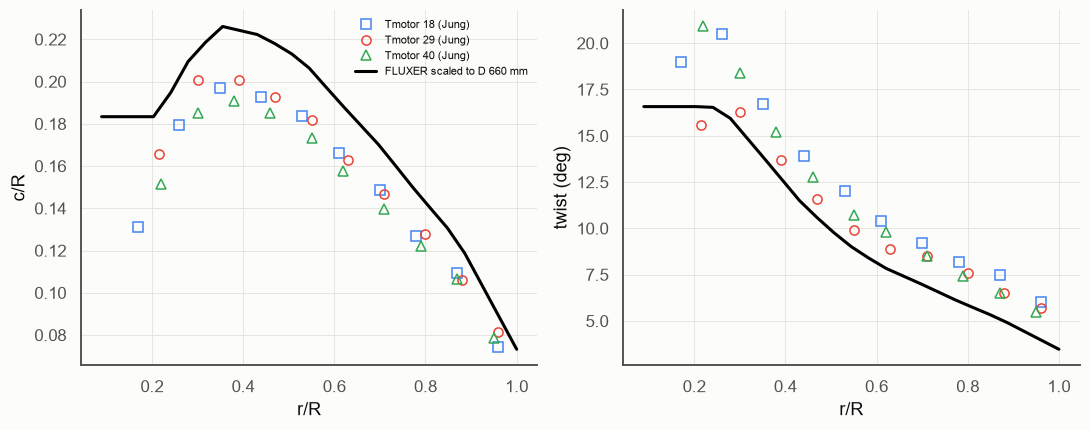

In [17]:
from component import jung_compare, jung_plot, scaled_blade
b = scaled_blade(model.c["rotor"], d["scale"])
chk_blade = jung_compare(b["r_over_R"], b["c_m"], b["beta_rad"], b["D_m"])
print({k: round(v, 4) if isinstance(v, float) else v for k, v in chk_blade.items() if k != "rows"})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
jung_plot(a1, a2, b["r_over_R"], b["c_m"], b["beta_rad"], b["D_m"], f"FLUXER scaled to D {b['D_m'] * 1000:.0f} mm")
fig.tight_layout();

## 9. Boom vibration

The boom must not be resonant at or near the hover speed. The chart shows the first bending frequency of a boom end (a cantilever from
the clamp with the rotor mass at the tip) against the rotor speed. The 2P line assumes a two-blade propeller. At full throttle the rotors
turn faster than the crossing. The crossing of f1 with 1P is a speed the rotors pass in spin-up and must not hold.

f2 is the second bending mode of the same cantilever (`Tube.modes_hz`: the exact beam equation with the tip mass and the tip
rotary inertia). The tip rotary inertia is an estimate: each prop as a rod of length D averaged over one turn, plus the tip mass at
the mount offset. The gyroscopic coupling of the turning prop is not modelled. f2 is a check after the solve, not a limit.

f1 = 18.2 Hz crosses 1P at 1092 rpm = 37 % of the hover speed
f1 Rayleigh 18.20 Hz, f1 exact 18.04 Hz (tip rotary inertia 1.47 g m2)
f2 = 221 Hz (without the tip rotary inertia 485 Hz)
f2 has no 1P crossing up to full throttle (4600 rpm, 1P = 77 Hz)
f2 has no 2P crossing up to full throttle (4600 rpm, 2P = 153 Hz)


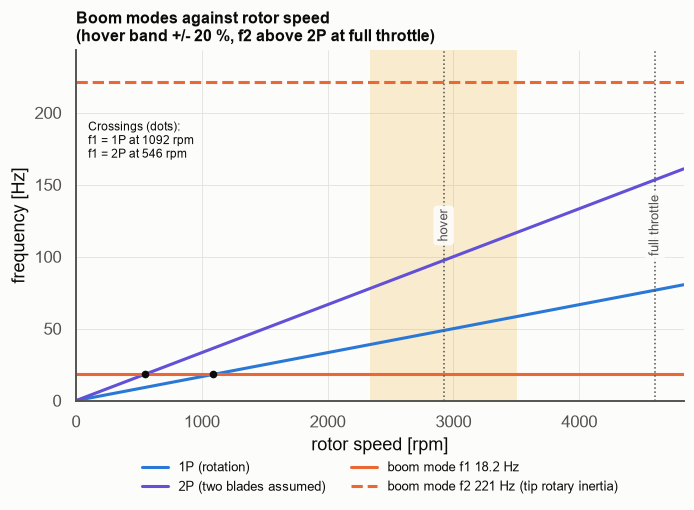

In [18]:
plot.frequency_chart(res);
rpm_h = res["rotors"]["H_TO_f"]["rpm"]
rpm_max = max(res["rotors"]["MAX_f"]["rpm"], res["rotors"]["MAX_r"]["rpm"])
rpm_cross = res["f1_Hz"] * 60
print(f"f1 = {res['f1_Hz']:.1f} Hz crosses 1P at {rpm_cross:.0f} rpm = {100 * rpm_cross / rpm_h:.0f} % of the hover speed")
print(f"f1 Rayleigh {res['f1_Hz']:.2f} Hz, f1 exact {res['f1_exact_Hz']:.2f} Hz (tip rotary inertia {res['boom_J_tip_kg_m2'] * 1e3:.2f} g m2)")
print(f"f2 = {res['f2_Hz']:.0f} Hz (without the tip rotary inertia {res['f2_no_J_Hz']:.0f} Hz)")
for k in (1, 2):
    rpm_x = 60 * res["f2_Hz"] / k
    print(f"f2 crosses {k}P at {rpm_x:.0f} rpm" if rpm_x <= rpm_max else
          f"f2 has no {k}P crossing up to full throttle ({rpm_max:.0f} rpm, {k}P = {k * rpm_max / 60:.0f} Hz)")

## 10. Checks

**Hand check of the tube.** The mass of the tube is density times section area times length. The first bending frequency is the
cantilever formula with a tip mass (Rayleigh: the tip mass plus 0.236 of the arm mass).

In [19]:
mat, bm = model.c["boom_material"], model.c["boom"]
r_o, t, a = d["r_boom"], d["t_boom"], d["a"]
L = 2 * a + 2 * bm["overhang_m"]
A = math.pi * (r_o**2 - (r_o - t) ** 2)
I = math.pi / 4 * (r_o**4 - (r_o - t) ** 4)
m_each = mat["density_kg_m3"] * A * L
m_tip = n["m_motor"] + n["m_prop"] + n["m_esc"] + model.c["motor"]["mount_kg"]
f1 = math.sqrt(3 * mat["E_Pa"] * I / (a**3 * (m_tip + 0.236 * m_each * a / L))) / (2 * math.pi)
print(f"tube mass each: by hand {1000 * m_each:.2f} g, solver {500 * n['m_boom']:.2f} g")
print(f"f1: by hand {f1:.3f} Hz, solver {res['f1_Hz']:.3f} Hz  (EI = {mat['E_Pa'] * I:.0f} N m2, tip mass {m_tip:.3f} kg)")
assert abs(1000 * m_each - 500 * n["m_boom"]) < 1e-6 and abs(f1 - res["f1_Hz"]) < 1e-6

tube mass each: by hand 145.72 g, solver 145.72 g


f1: by hand 18.197 Hz, solver 18.197 Hz  (EI = 457 N m2, tip mass 0.568 kg)


**Every value fixed.** The design is fixed at the optimum (only the battery x closes the CG). Every limit must hold and the energy must not
change.

In [20]:
chk = model.copy()
for name, (ck, pk) in DESIGN_VARS.items():
    chk.c[ck].params[pk].value = float(d[name])
back = evaluate(chk, "L4")
print("limits broken:", back.violated() or "none", "| energy difference:", f"{100 * (back.energy_Wh / res.energy_Wh - 1):+.4f} %")
assert not back.violated() and abs(back.energy_Wh / res.energy_Wh - 1) < 1e-3

limits broken: none | energy difference: +0.0000 %


## 11. Save the model

`settings/rosella.json` holds the components with every param, its units and its source, the free and fixed state, and the summary of
this result. The AeroSandbox spoke reads it into the aircraft source tree (`python -m aeroplan ingest AeroSandbox rosella`).

In [21]:
model.result_summary = res.compact()
path = model.save()
res.save(TOOL.parents[1] / "work" / "aerosandbox" / "rosella" / "sizing" / "best.json")
print(path.relative_to(TOOL.parents[1]), f"{path.stat().st_size / 1024:.0f} kB")

tools\aerosandbox\settings\rosella.json 51 kB


## 12. Change a few params and watch the design

The window lists the params of every component. Change a value and the 3D view moves. **Evaluate** keeps every param fixed and shows
the limits that break. **Optimise** frees the rows marked "free" and redraws the booms and rotors at each solver iteration.
Level L1 takes seconds, L4 takes about a minute. The window works in a live notebook only.

In [22]:
from window import Window
win = Window(model, "L4").show()